# SAMATRIX RESUMEFORGE 2026: END-TO-END NLP RESUME CLASSIFICATION
### A Complete Phase-Wise NLP Lifecycle (Total: 70 Marks)
**Workflow: Problem Definition → Data Gathering → Quality Audit → EDA → Text Preprocessing → Stratified Split → Feature Engineering → Classical & Deep Learning Models → Multi-Metric Evaluation → Error Analysis → Inference Pipeline & Testing**

This notebook fulfills all 12 stages specified in the official **Problem statement and Guidelines for Hackathon.docx** with zero data leakage, reproducible preprocessing, and comprehensive diagnostics.

In [1]:
# Setup Environment and Imports
import os
import re
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from collections import Counter
from pathlib import Path

# Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# Configuration Constants
RANDOM_STATE = 42
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15
# Support running this notebook from either the project root or notebooks/.
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "Dataset").exists() else Path.cwd().parent
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
MODELS_DIR = ARTIFACTS_DIR / "models"
REPORTS_DIR = ARTIFACTS_DIR / "reports"
FIGURES_DIR = ARTIFACTS_DIR / "figures"
CACHE_PATH = ARTIFACTS_DIR / "processed_data_cache.joblib"

# Create artifact directories
MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Environment configured successfully. Project root: {PROJECT_ROOT}")

Environment configured successfully. Project root: D:\ResumeForge


In [2]:
# Load the Phase 3 test partition and Phase 4 winner explicitly.
required_paths = [CACHE_PATH, MODELS_DIR / "best_model.joblib", MODELS_DIR / "label_encoder.joblib"]
missing_paths = [str(path) for path in required_paths if not path.exists()]
if missing_paths:
    raise FileNotFoundError(
        "Required artifacts are missing. Run Phase 3 and Phase 4 first: " + ", ".join(missing_paths)
    )

cache = joblib.load(CACHE_PATH)
X_test, y_test = cache["X_test"], cache["y_test"]
test_raw = list(cache["test_raw_texts"])
test_clean = list(cache["test_clean_texts"])
test_actual = list(cache["test_categories"])
best_model = joblib.load(MODELS_DIR / "best_model.joblib")
le = joblib.load(MODELS_DIR / "label_encoder.joblib")

comparison_path = REPORTS_DIR / "model_comparison.json"
comparison = json.loads(comparison_path.read_text(encoding="utf-8")) if comparison_path.exists() else {}
best_model_name = comparison.get("best_model", type(best_model).__name__)
print(f"Loaded {best_model_name}; test matrix: {X_test.shape}; labels: {len(le.classes_)}")

Loaded Linear_SVM; test matrix: (373, 12000); labels: 24


---
## 🎯 STAGE 10: Multi-Metric Evaluation on Untouched Test Set (5 Marks)
Evaluate the winning model on the **373 test resumes** that were held out.
Compute Accuracy, Precision, Recall, Macro-F1, Weighted-F1, and plot the normalized Confusion Matrix.

STAGE 10: UNTOUCHED TEST SET EVALUATION
• Test Accuracy        : 74.53%
• Test Macro-Precision : 0.7120
• Test Macro-Recall    : 0.7069
• Test Macro-F1        : 0.7008
• Test Weighted-F1     : 0.7334


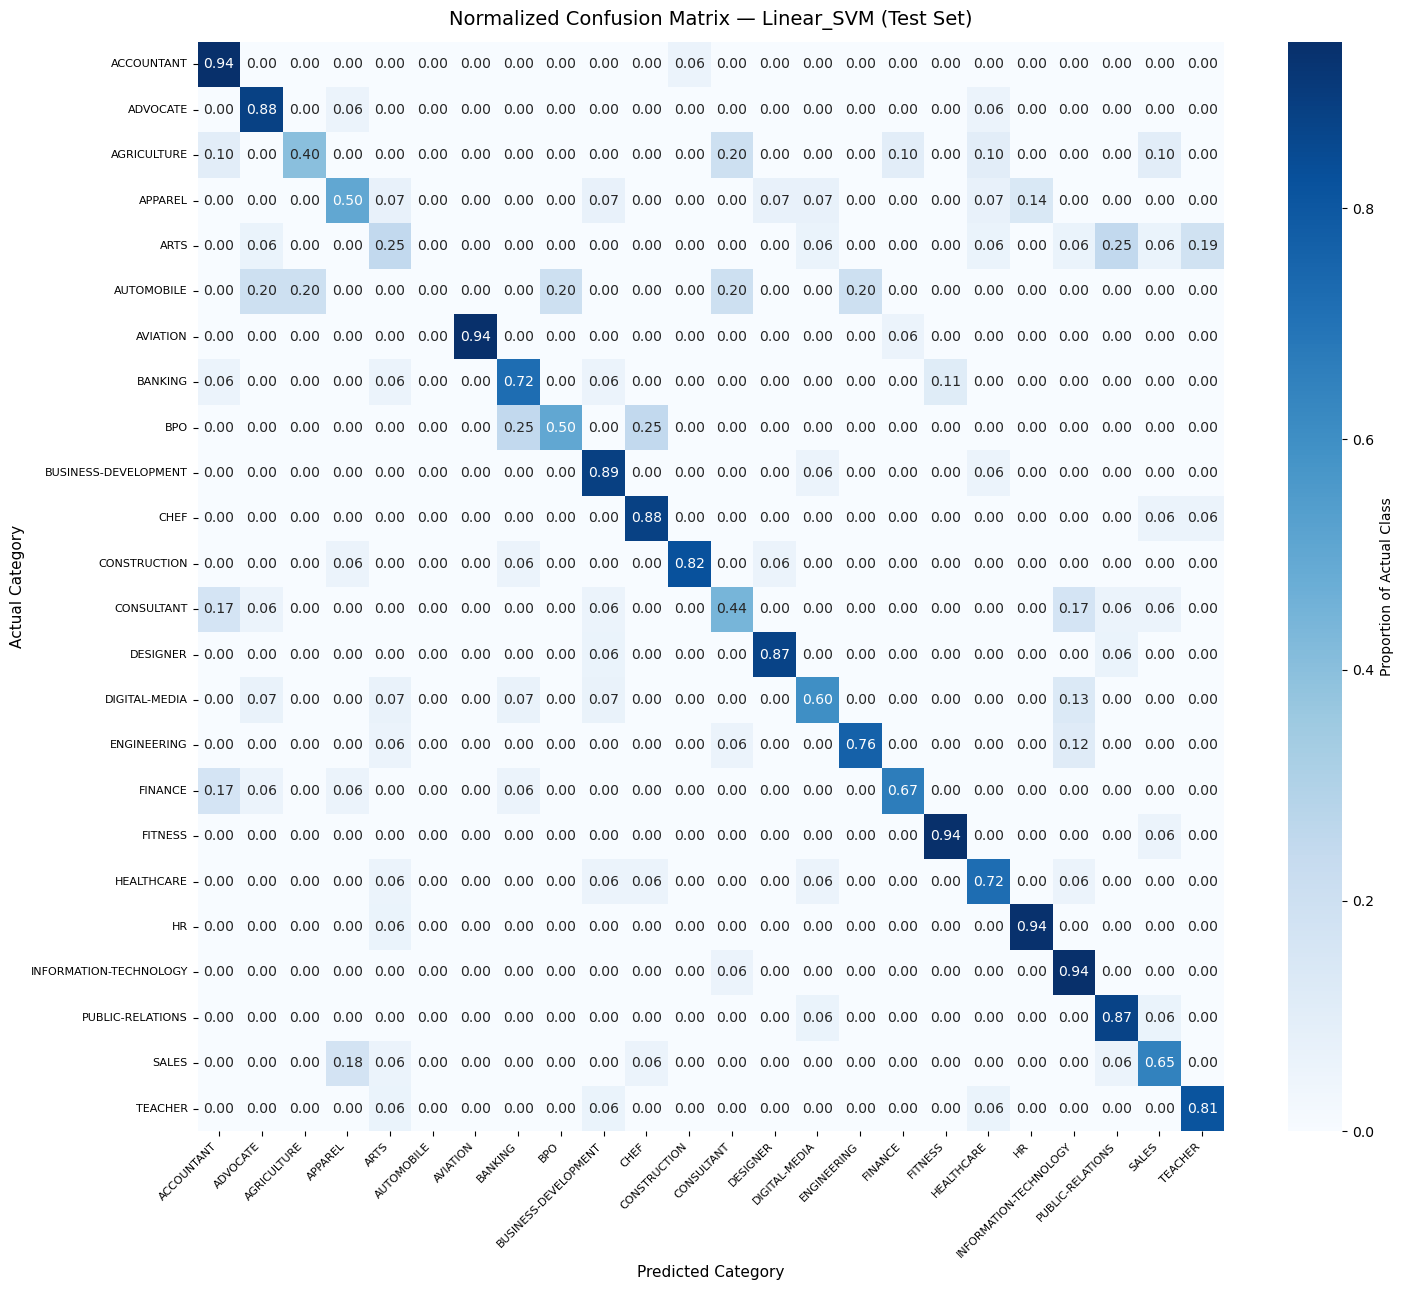

Saved per-class classification report to D:\ResumeForge\artifacts\reports\classification_report.csv


In [3]:
# Stage 10: Final Test Set Evaluation
target_names = list(le.classes_)
y_test_pred = best_model.predict(X_test)

test_acc = accuracy_score(y_test, y_test_pred)
test_macro_p = precision_score(y_test, y_test_pred, average="macro", zero_division=0)
test_macro_r = recall_score(y_test, y_test_pred, average="macro", zero_division=0)
test_macro_f1 = f1_score(y_test, y_test_pred, average="macro", zero_division=0)
test_weighted_f1 = f1_score(y_test, y_test_pred, average="weighted", zero_division=0)

print("="*55)
print("STAGE 10: UNTOUCHED TEST SET EVALUATION")
print("="*55)
print(f"• Test Accuracy        : {test_acc*100:.2f}%")
print(f"• Test Macro-Precision : {test_macro_p:.4f}")
print(f"• Test Macro-Recall    : {test_macro_r:.4f}")
print(f"• Test Macro-F1        : {test_macro_f1:.4f}")
print(f"• Test Weighted-F1     : {test_weighted_f1:.4f}")
print("="*55)

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_test_pred)
cm_norm = cm.astype('float') / (cm.sum(axis=1)[:, np.newaxis] + 1e-9)

plt.figure(figsize=(15, 13))
sns.heatmap(
    cm_norm, annot=True, fmt=".2f", cmap="Blues",
    xticklabels=target_names, yticklabels=target_names,
    cbar_kws={'label': 'Proportion of Actual Class'}
)
plt.title(f"Normalized Confusion Matrix — {best_model_name} (Test Set)", fontsize=14, pad=12)
plt.xlabel("Predicted Category", fontsize=11)
plt.ylabel("Actual Category", fontsize=11)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "test_confusion_matrix.png", dpi=300)
plt.show()

# Save per-class classification report
cls_report = classification_report(y_test, y_test_pred, target_names=target_names, output_dict=True)
pd.DataFrame(cls_report).transpose().to_csv(REPORTS_DIR / "classification_report.csv")
print(f"Saved per-class classification report to {REPORTS_DIR / 'classification_report.csv'}")

---
## 🔍 STAGE 11: In-Depth Error Analysis (5 Marks)
Examine all test set misclassifications:
- Compare Actual vs. Predicted labels
- Inspect model confidence scores
- Identify frequent cross-category confusion pairs
- Diagnose failure causes (e.g. `CONSULTANT` ↔ `INFORMATION-TECHNOLOGY`, `FINANCE` ↔ `ACCOUNTANT`)

In [4]:
# Stage 11: Diagnostic Error Analysis
test_pred_labels = [target_names[i] for i in y_test_pred]

if hasattr(best_model, "predict_proba"):
    test_probs = best_model.predict_proba(X_test)
else:
    test_probs = np.zeros((len(y_test), len(target_names)))

errors = []
for i in range(len(y_test)):
    if test_actual[i] != test_pred_labels[i]:
        conf = float(np.max(test_probs[i]))
        errors.append({
            "Actual": test_actual[i],
            "Predicted": test_pred_labels[i],
            "Confidence": round(conf, 4),
            "Word_Count": len(test_clean[i].split()),
            "Snippet": test_clean[i][:180]
        })

df_err = pd.DataFrame(errors)
print(f"Total Misclassifications Diagnosed: {len(df_err)} out of {len(y_test)} test samples\n")

print("Top 8 Most Frequent Confused Pairs:")
confusion_pairs = (
    df_err.groupby(["Actual", "Predicted"])
    .size()
    .reset_index(name="Count")
    .sort_values(by="Count", ascending=False)
)
display(confusion_pairs.head(8))

df_err.to_csv(REPORTS_DIR / "error_analysis.csv", index=False)
print(f"Saved detailed error analysis to {REPORTS_DIR / 'error_analysis.csv'}")

Total Misclassifications Diagnosed: 95 out of 373 test samples

Top 8 Most Frequent Confused Pairs:


,Actual,Predicted,Count
18,ARTS,PUBLIC-RELATIONS,4
20,ARTS,TEACHER,3
70,SALES,APPAREL,3
43,CONSULTANT,INFORMATION-TECHNOLOGY,3
56,FINANCE,ACCOUNTANT,3
40,CONSULTANT,ACCOUNTANT,3
55,ENGINEERING,INFORMATION-TECHNOLOGY,2
52,DIGITAL-MEDIA,INFORMATION-TECHNOLOGY,2


Saved detailed error analysis to D:\ResumeForge\artifacts\reports\error_analysis.csv
